# EDA: the anime table

What the catalog looks like and how user activity is spread over it.

Inputs: `data/clean/anime.parquet` (one row per anime) and
`tables/anime_stats.parquet` (rating counts per anime, from
`python -m cleaning.03_eda.aggregates`).

Catalog numbers (`score`, `members`, `favorites`, `rank`) are MAL's own, crawled on
2026-11-16, after every rating in the dataset. A model evaluated on a time split must not
use them as features for the test period.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import config, plotting
from cleaning.plotting import BLUE, MUTED, ORANGE

plotting.use_style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(60)

anime = pl.read_parquet(config.CLEAN_ANIME)
stats = pl.read_parquet(config.TABLES / "anime_stats.parquet")
df = anime.join(stats, on="anime_id", how="left").with_columns(
    pl.col("n_ratings").fill_null(0),
    start_year=pl.col("start_date").dt.year(),
    n_watched=(pl.col("n_completed") + pl.col("n_watching")).fill_null(0),
)
total = df["n_ratings"].sum()
print(f"{anime.height:,} anime, {(df['n_ratings'] > 0).sum():,} appear in at least one list, "
      f"{total:,} rating rows")


def hbar(ax, labels, values, fmt="{:,.0f}", color=BLUE):
    bars = ax.barh(labels, values, color=color, height=0.65)
    ax.bar_label(bars, labels=[" " + fmt.format(v) for v in values], color=MUTED, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(values) * 1.18)
    ax.grid(axis="y", visible=False)

30,801 anime, 30,408 appear in at least one list, 548,928,922 rating rows


## 1. Field coverage

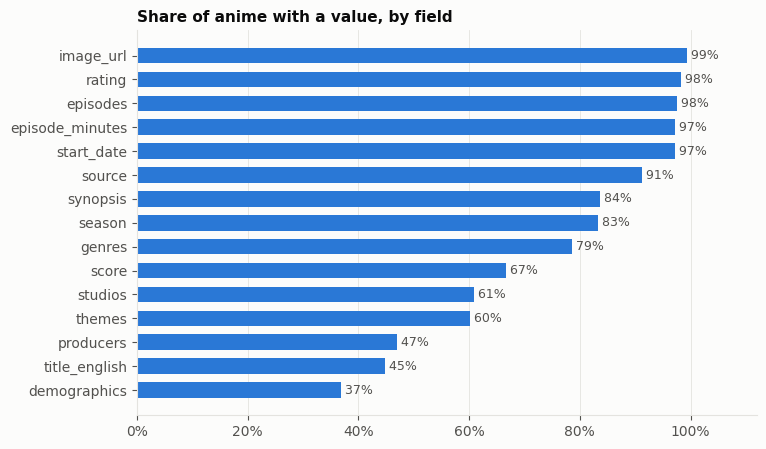

In [2]:
fields = ["synopsis", "score", "episodes", "episode_minutes", "start_date", "season", "rating", "source",
          "title_english", "image_url"]
lists = ["genres", "themes", "demographics", "studios", "producers"]
coverage = {f: 1 - anime[f].null_count() / anime.height for f in fields}
coverage.update({f: (anime[f].list.len().fill_null(0) > 0).mean() for f in lists})
order = sorted(coverage, key=coverage.get, reverse=True)
fig, ax = plt.subplots(figsize=(8, 5))
hbar(ax, order, [coverage[f] for f in order], fmt="{:.0%}")
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Share of anime with a value, by field")
plt.show()

Identity and format fields are nearly complete. The gaps matter for content features: MAL
shows a score for only 67% of anime (it needs enough voters), 84% have a synopsis, 79% have
genres, 61% studios, 60% themes, 47% producers and 37% a demographic. A missing tag usually
means an obscure title, so "untagged" is information in itself.

## 2. Format, source and age rating

Left: how many anime of each kind exist. Right: where the user activity goes.

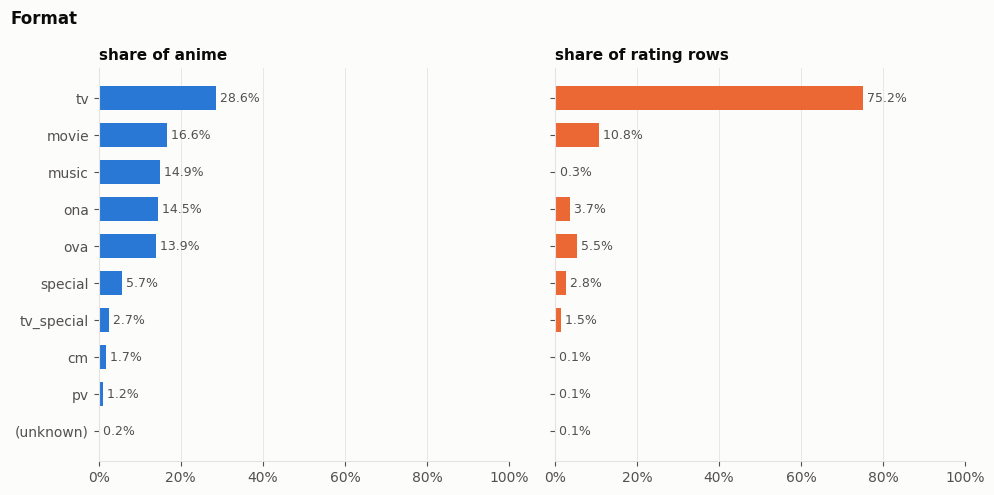

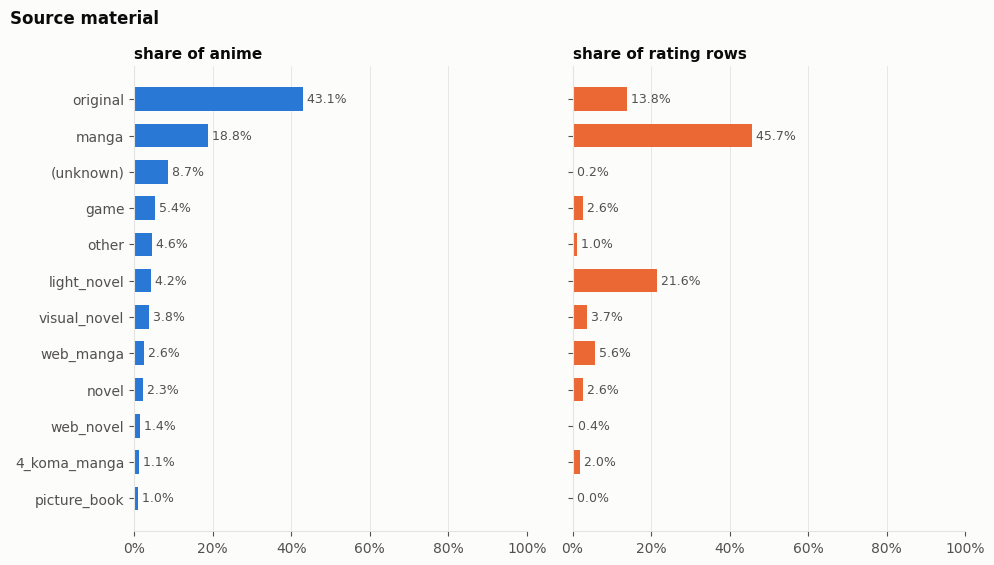

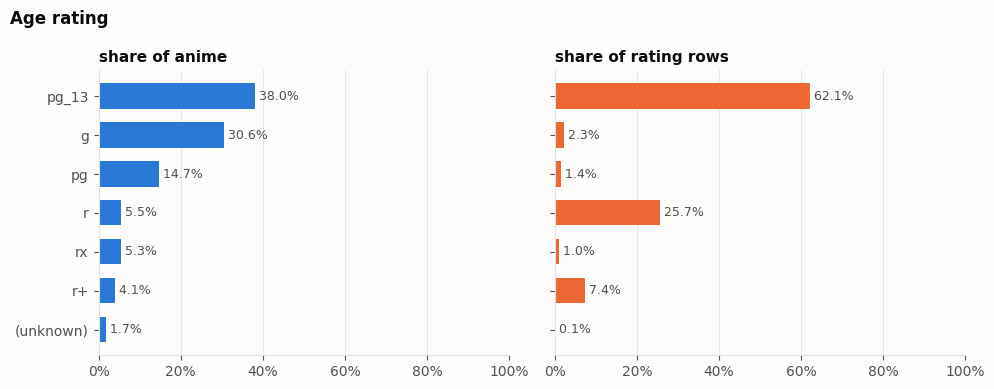

In [3]:
def catalog_vs_activity(column, title):
    g = (df.group_by(column).agg(pl.len().alias("anime"), pl.col("n_ratings").sum().alias("ratings"))
           .with_columns(pl.col(column).fill_null("(unknown)")).sort("anime", descending=True).head(12))
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.36 * g.height + 1.4), sharey=True)
    hbar(axes[0], g[column].to_list(), (g["anime"] / anime.height).to_list(), fmt="{:.1%}")
    hbar(axes[1], g[column].to_list(), (g["ratings"] / total).to_list(), fmt="{:.1%}", color=ORANGE)
    axes[0].invert_yaxis()
    for ax, name in zip(axes, ("share of anime", "share of rating rows")):
        ax.set_title(name)
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


catalog_vs_activity("media_type", "Format")
catalog_vs_activity("source", "Source material")
catalog_vs_activity("rating", "Age rating")

Activity is far more concentrated than the catalog. TV series are 29% of the anime and 75% of
the rating rows; music videos, commercials and promos are 18% of the catalog and under 1% of
the rows. Manga and light-novel adaptations are 23% of the catalog and 67% of the rows, while
original works (43% of the catalog, largely shorts and music videos) get 14%. Ratings G and PG
cover 45% of the catalog but under 4% of the rows: this audience watches PG-13 and R titles.

## 3. Release year

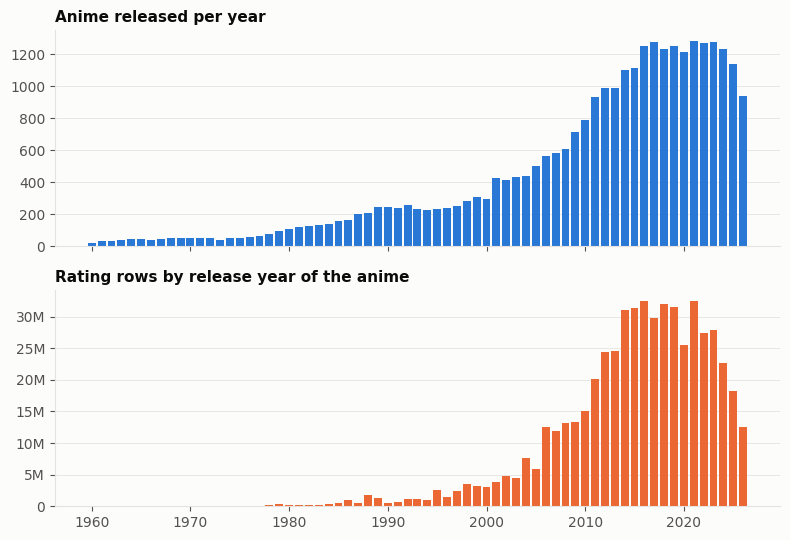

anime from 2016 on: 44.0% of the catalog, 53.6% of the rating rows
shape: (6, 4)
┌────────────┬───────┬──────────┬──────────────────────────┐
│ start_year ┆ anime ┆ ratings  ┆ median ratings per anime │
│ ---        ┆ ---   ┆ ---      ┆ ---                      │
│ i32        ┆ u32   ┆ u32      ┆ f64                      │
╞════════════╪═══════╪══════════╪══════════════════════════╡
│ 2023       ┆ 1273  ┆ 27920085 ┆ 403.0                    │
│ 2024       ┆ 1234  ┆ 22661179 ┆ 326.5                    │
│ 2025       ┆ 1138  ┆ 18180200 ┆ 312.0                    │
│ 2026       ┆ 937   ┆ 12536074 ┆ 280.0                    │
│ 2027       ┆ 202   ┆ 1604242  ┆ 1321.5                   │
│ 2028       ┆ 6     ┆ 38007    ┆ 2997.0                   │
└────────────┴───────┴──────────┴──────────────────────────┘


In [4]:
by_year = (df.filter(pl.col("start_year").is_between(1960, 2026))
             .group_by("start_year").agg(pl.len().alias("anime"), pl.col("n_ratings").sum().alias("ratings"))
             .sort("start_year"))
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
axes[0].bar(by_year["start_year"], by_year["anime"], color=BLUE, width=0.8)
axes[0].set_title("Anime released per year")
axes[1].bar(by_year["start_year"], by_year["ratings"], color=ORANGE, width=0.8)
axes[1].set_title("Rating rows by release year of the anime")
plotting.thousands(axes[1])
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
recent = df.filter(pl.col("start_year") >= 2016)
print(f"anime from 2016 on: {recent.height / anime.height:.1%} of the catalog, "
      f"{recent['n_ratings'].sum() / total:.1%} of the rating rows")
print(df.filter(pl.col("start_year") >= 2023).group_by("start_year")
        .agg(pl.len().alias("anime"), pl.col("n_ratings").sum().alias("ratings"),
             pl.col("n_ratings").median().alias("median ratings per anime")).sort("start_year"))

Output has been flat at 1,200 to 1,300 anime a year since 2016, and activity follows the
release year: anime from 2016 on are 44% of the catalog and 54% of the rows. The most recent
years are lower only because their audience is still arriving (the ratings stop in October
2026). The catalog was crawled a month after the ratings, so titles dated 2027 and 2028 exist
only as plan-to-watch entries.

## 4. Genres and themes

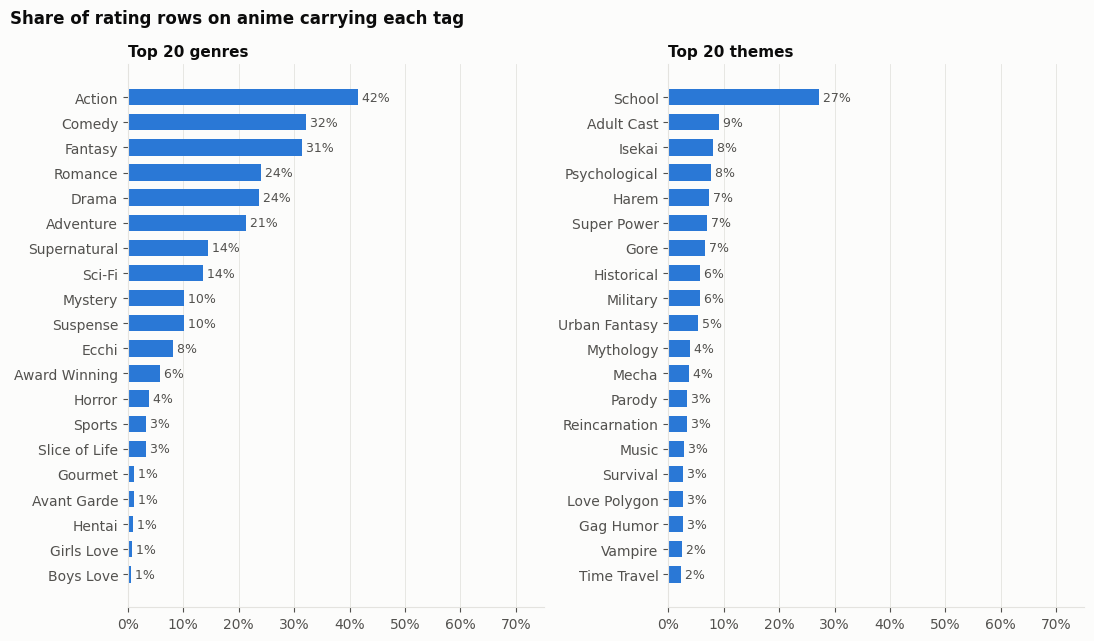

demographics: [('Shounen', 2347, 0.292), ('Seinen', 1232, 0.11), ('Shoujo', 553, 0.033), ('Kids', 7133, 0.009), ('Josei', 162, 0.009)]


In [5]:
def tag_table(column):
    return (df.select(column, "n_ratings").explode(column).drop_nulls()
              .group_by(column).agg(pl.len().alias("anime"), pl.col("n_ratings").sum().alias("ratings"))
              .sort("ratings", descending=True))


fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
for ax, column in zip(axes, ("genres", "themes")):
    t = tag_table(column).head(20)
    hbar(ax, t[column].to_list(), (t["ratings"] / total).to_list(), fmt="{:.0%}")
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(f"Top 20 {column}")
fig.suptitle("Share of rating rows on anime carrying each tag", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
print("demographics:", tag_table("demographics").with_columns((pl.col("ratings") / total).round(3)).rows())

An anime carries several tags, so the bars do not sum to 100%. Action, Comedy and Fantasy
dominate, and School is by far the most common theme (27% of rows). By demographic, Shounen
titles take 29% of the rows and Seinen 11%. Kids anime are the largest demographic in the
catalog (7,133 titles) and get under 1% of the rows.

## 5. The long tail of popularity

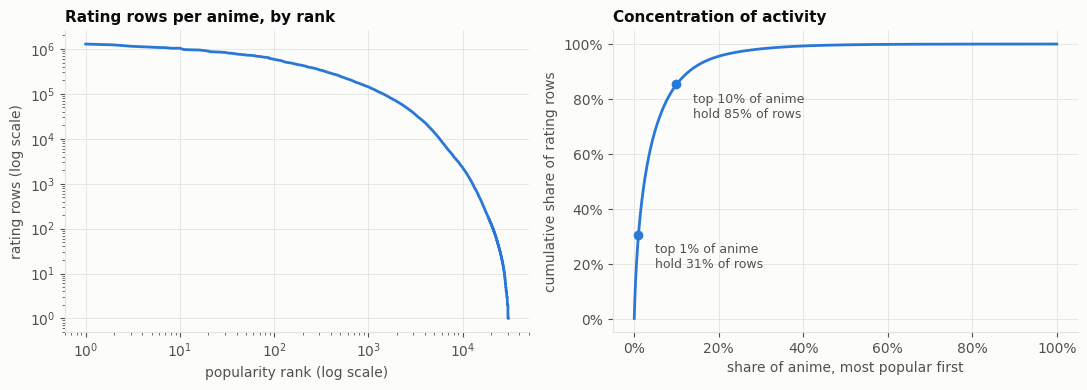

anime with at least       1 rating rows: 30,408 (98.7%)
anime with at least      10 rating rows: 27,724 (90.0%)
anime with at least      20 rating rows: 26,157 (84.9%)
anime with at least     100 rating rows: 20,978 (68.1%)
anime with at least   1,000 rating rows: 12,726 (41.3%)
anime with at least  10,000 rating rows:  5,688 (18.5%)
anime with at least 100,000 rating rows:  1,436 (4.7%)


In [6]:
counts = np.sort(df["n_ratings"].to_numpy())[::-1]
cum = np.cumsum(counts) / counts.sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rank = np.arange(1, len(counts) + 1)
axes[0].plot(rank[counts > 0], counts[counts > 0], color=BLUE)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("popularity rank (log scale)"); axes[0].set_ylabel("rating rows (log scale)")
axes[0].set_title("Rating rows per anime, by rank")
axes[1].plot(rank / len(counts), cum, color=BLUE)
for share in (0.01, 0.1):
    k = int(len(counts) * share)
    axes[1].plot([share], [cum[k - 1]], "o", color=BLUE, ms=6)
    axes[1].annotate(f"top {share:.0%} of anime\nhold {cum[k - 1]:.0%} of rows", (share, cum[k - 1]),
                     xytext=(12, -24), textcoords="offset points", color=MUTED, fontsize=9)
axes[1].set_xlabel("share of anime, most popular first"); axes[1].set_ylabel("cumulative share of rating rows")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_title("Concentration of activity")
plt.tight_layout()
plt.show()
for k in (1, 10, 20, 100, 1_000, 10_000, 100_000):
    n = (df["n_ratings"] >= k).sum()
    print(f"anime with at least {k:>7,} rating rows: {n:>6,} ({n / anime.height:.1%})")

Popularity is extremely skewed: the top 1% of anime (about 300 titles) hold 31% of all rows and
the top 10% hold 85%. At the other end, 15% of the catalog has fewer than 20 rows and 393 anime
appear in no list at all. Any minimum-interaction threshold on anime therefore removes a large
part of the catalog while touching very few rows, and the anime below it are exactly the ones
a content-based or cold-start component has to cover.

## 6. Scores

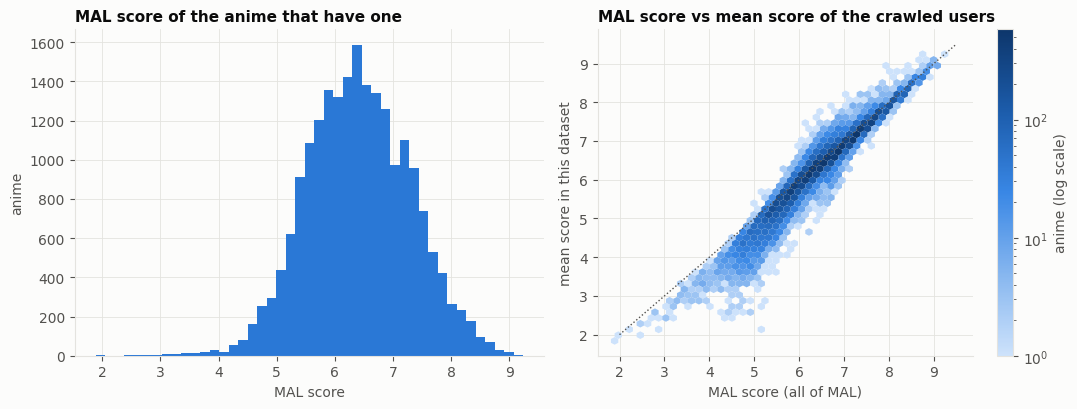

anime with >= 50 scores here: 19,003; correlation 0.972; mean difference (dataset - MAL) -0.15


In [7]:
scored = df.filter((pl.col("n_scored") >= 50) & pl.col("score").is_not_null()).with_columns(
    crawl_mean=pl.col("score_sum") / pl.col("n_scored"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(anime["score"].drop_nulls(), bins=45, color=BLUE)
axes[0].set_xlabel("MAL score"); axes[0].set_ylabel("anime")
axes[0].set_title("MAL score of the anime that have one")
hb = axes[1].hexbin(scored["score"], scored["crawl_mean"], gridsize=45, cmap=plotting.SEQUENTIAL, bins="log", mincnt=1)
axes[1].plot([2, 9.5], [2, 9.5], color=MUTED, lw=1, ls=":")
axes[1].set_xlabel("MAL score (all of MAL)"); axes[1].set_ylabel("mean score in this dataset")
axes[1].set_title("MAL score vs mean score of the crawled users")
fig.colorbar(hb, ax=axes[1], label="anime (log scale)")
plt.tight_layout()
plt.show()
print(f"anime with >= 50 scores here: {scored.height:,}; "
      f"correlation {np.corrcoef(scored['score'].to_numpy(), scored['crawl_mean'].to_numpy())[0, 1]:.3f}; "
      f"mean difference (dataset - MAL) {(scored['crawl_mean'] - scored['score']).mean():+.2f}")

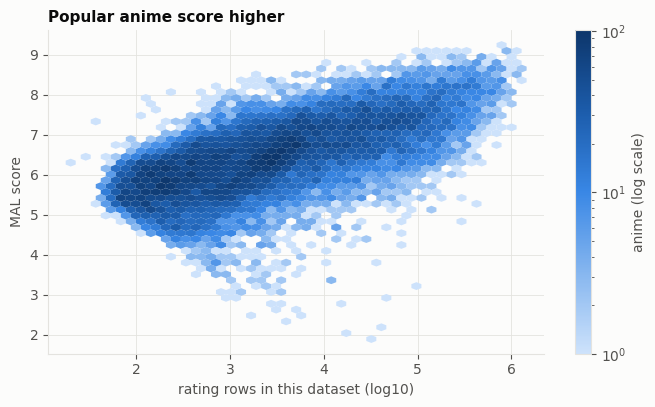

In [8]:
pop = df.filter((pl.col("n_ratings") >= 20) & pl.col("score").is_not_null())
fig, ax = plt.subplots(figsize=(8, 4.2))
hb = ax.hexbin(np.log10(pop["n_ratings"]), pop["score"], gridsize=45, cmap=plotting.SEQUENTIAL, bins="log", mincnt=1)
ax.set_xlabel("rating rows in this dataset (log10)"); ax.set_ylabel("MAL score")
ax.set_title("Popular anime score higher")
fig.colorbar(hb, ax=ax, label="anime (log scale)")
plt.show()

MAL scores are compressed: 90% of scored anime sit between 5.0 and 7.9, with a median of 6.4.
The crawled users agree with MAL almost perfectly (correlation 0.97 over 19,003 anime) while
scoring 0.15 lower on average. Score rises with popularity, so "popular" and "well rated" are
hard to tell apart: a model that only learns popularity will look as if it learned quality.

## 7. What users do with an anime: status mix

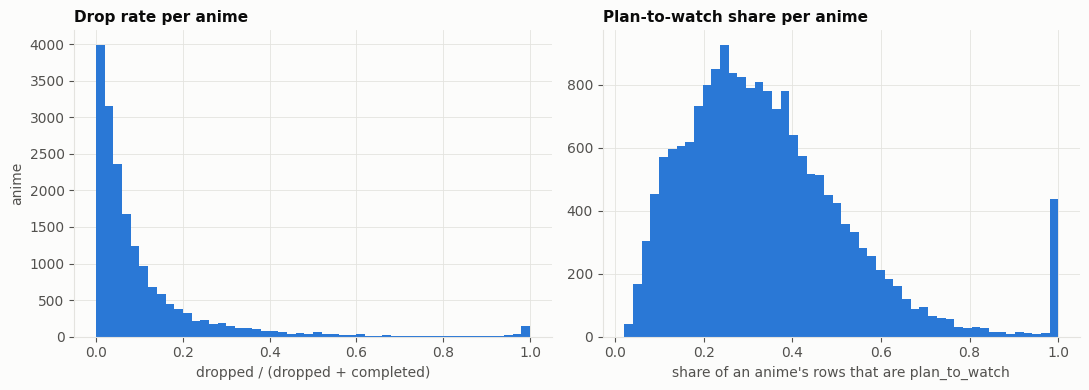

anime with >= 200 rows: 18,232; median drop rate 5.6%, median plan_to_watch share 31.5%
shape: (3, 3)
┌──────────────────┬───────┬───────────────────┐
│ status           ┆ anime ┆ median plan share │
│ ---              ┆ ---   ┆ ---               │
│ str              ┆ u32   ┆ f64               │
╞══════════════════╪═══════╪═══════════════════╡
│ finished_airing  ┆ 17658 ┆ 0.308928          │
│ not_yet_aired    ┆ 351   ┆ 0.999469          │
│ currently_airing ┆ 223   ┆ 0.468512          │
└──────────────────┴───────┴───────────────────┘


In [9]:
mix = df.filter(pl.col("n_ratings") >= 200).with_columns(
    drop_rate=pl.col("n_dropped") / (pl.col("n_dropped") + pl.col("n_completed")),
    plan_share=pl.col("n_plan_to_watch") / pl.col("n_ratings"),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(mix["drop_rate"].drop_nulls(), bins=50, color=BLUE)
axes[0].set_xlabel("dropped / (dropped + completed)"); axes[0].set_ylabel("anime")
axes[0].set_title("Drop rate per anime")
axes[1].hist(mix["plan_share"], bins=50, color=BLUE)
axes[1].set_xlabel("share of an anime's rows that are plan_to_watch")
axes[1].set_title("Plan-to-watch share per anime")
plt.tight_layout()
plt.show()
print(f"anime with >= 200 rows: {mix.height:,}; median drop rate {mix['drop_rate'].median():.1%}, "
      f"median plan_to_watch share {mix['plan_share'].median():.1%}")
by_status = (mix.group_by("status").agg(pl.len().alias("anime"), pl.col("plan_share").median().alias("median plan share"))
               .sort("anime", descending=True))
print(by_status)

Most anime are rarely dropped (median drop rate 5.6%), with a long tail of titles that lose
more than a third of their viewers. Plan-to-watch is a large part of every anime's footprint,
a median 31% of its rows. The spike at 100% is unreleased anime: for the 351 not-yet-aired
titles practically every row is plan_to_watch, which is the only signal that exists for an
anime before it airs.